In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
filename = "G:/neural_network_from_scratch/heart diseases/heart.csv"
df = pd.read_csv(filename)
df.head(1)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0


In [3]:
chest_pain_df = df.groupby(['ChestPainType','HeartDisease']).size().reset_index(name="count")
chest_pain_df

,ChestPainType,HeartDisease,count
0,ASY,0,104
1,ASY,1,392
2,ATA,0,149
3,ATA,1,24
4,NAP,0,131
5,NAP,1,72
6,TA,0,26
7,TA,1,20


Text(0.5, 1.0, 'Cholesterol Level Distribution')

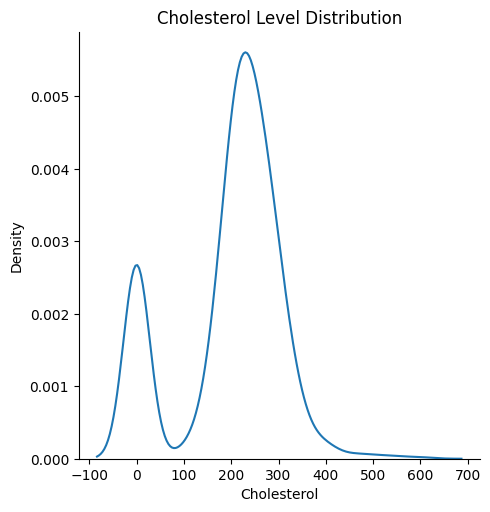

In [4]:
sns.displot(df,x="Cholesterol",kind="kde")
plt.title("Cholesterol Level Distribution")

Text(0.5, 1.0, 'Chest Pain Type with heart disease')

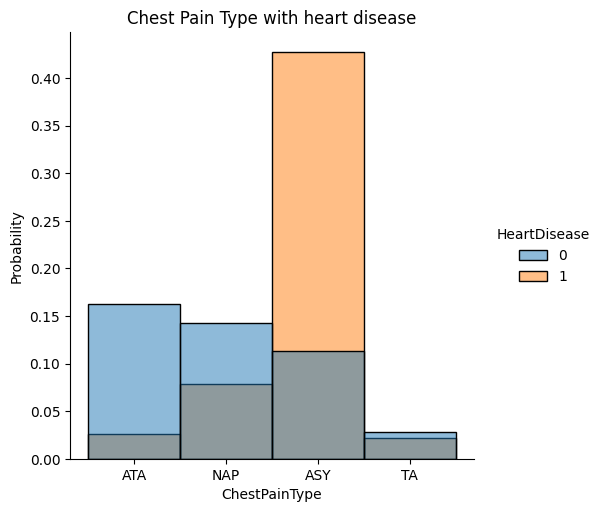

In [5]:
sns.displot(df,x="ChestPainType",hue="HeartDisease",stat="probability")
plt.title("Chest Pain Type with heart disease")

Text(0.5, 1.0, 'Cholesterol Level with Heart disease')

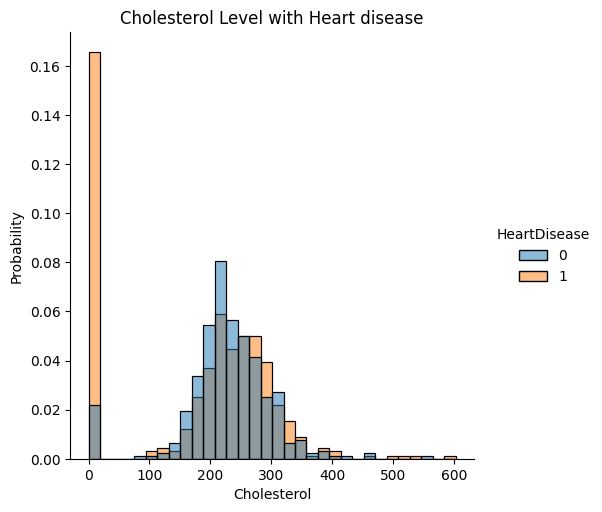

In [6]:
sns.displot(df,x="Cholesterol",hue="HeartDisease",stat="probability")
plt.title("Cholesterol Level with Heart disease")

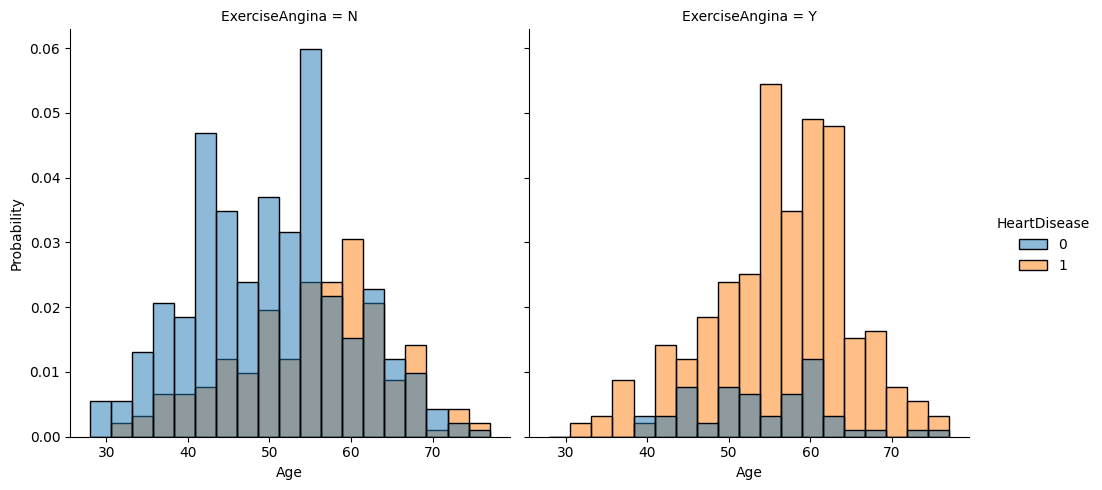

In [7]:
sns.displot(df,x="Age",hue="HeartDisease",col="ExerciseAngina",stat="probability")

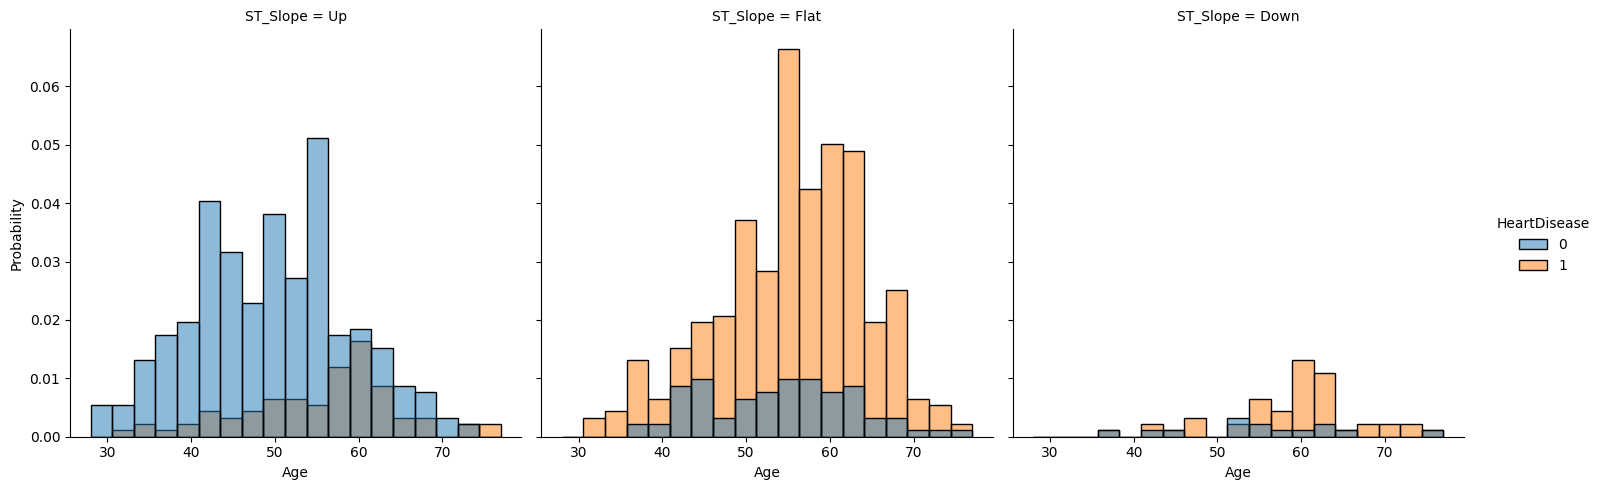

In [8]:
sns.displot(df,x="Age",hue="HeartDisease",col="ST_Slope",stat="probability")

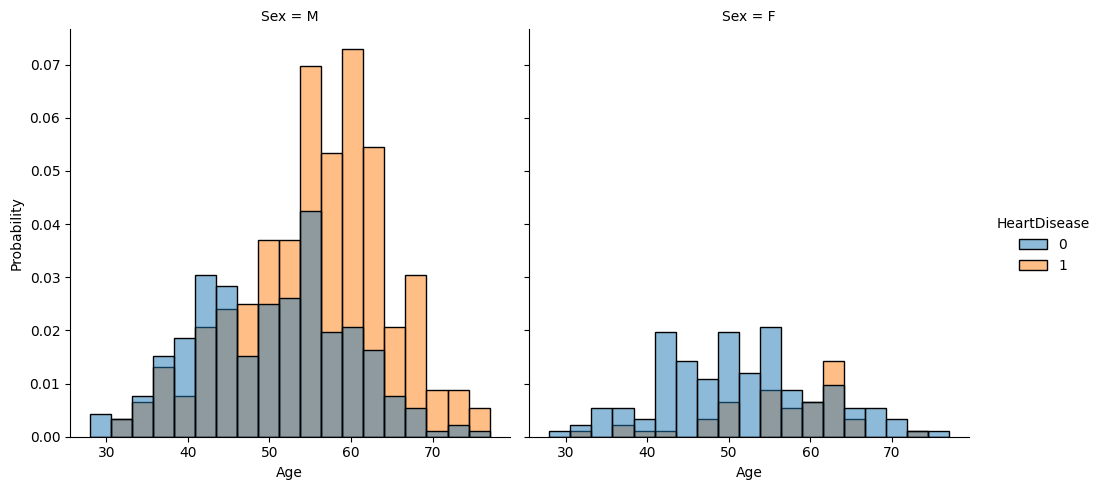

In [9]:
sns.displot(df,x="Age",hue="HeartDisease",col="Sex",stat="probability")

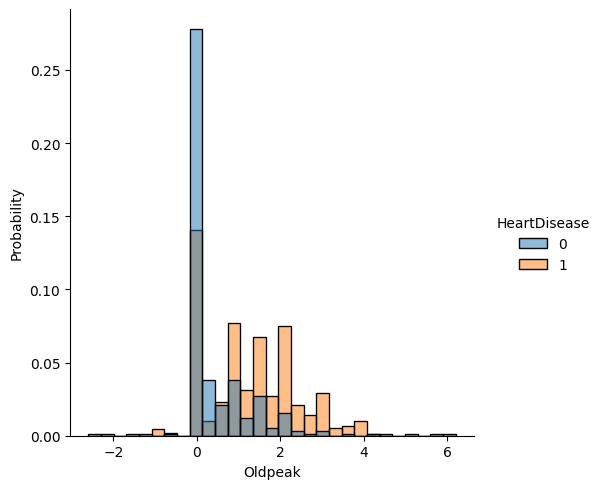

In [10]:
sns.displot(df,x="Oldpeak",hue="HeartDisease",stat="probability")

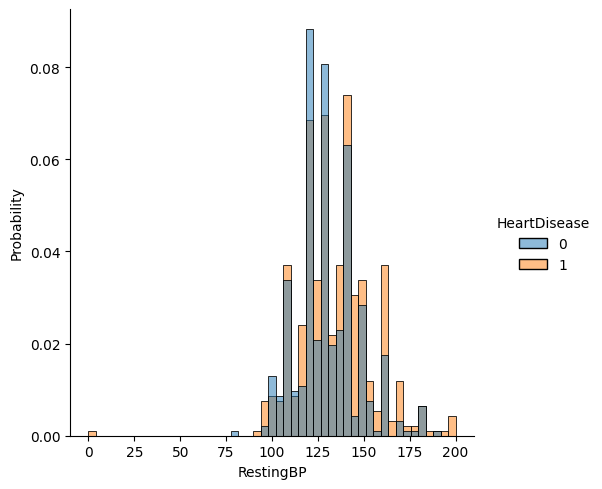

In [11]:
sns.displot(df,x="RestingBP",hue="HeartDisease",stat="probability")

In [12]:
df.head(1)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0


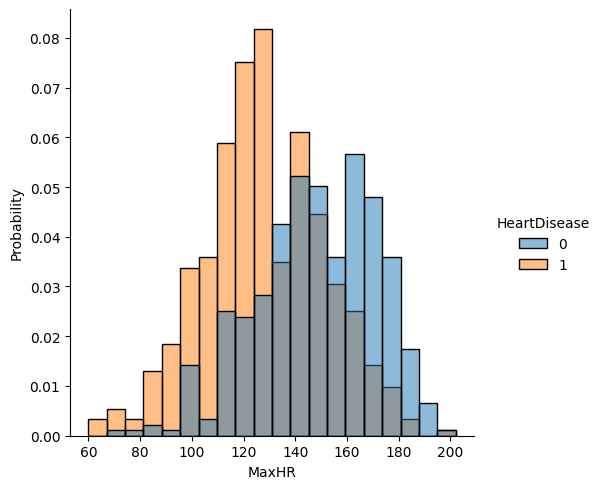

In [13]:
sns.displot(df,x="MaxHR",hue="HeartDisease",stat="probability")

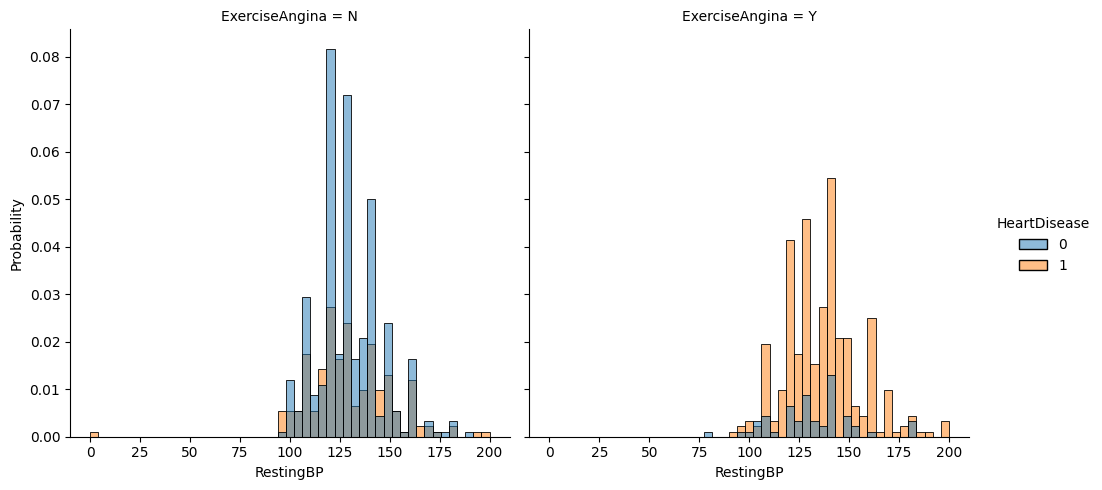

In [14]:
sns.displot(df,x="RestingBP",hue="HeartDisease",col="ExerciseAngina",stat="probability")

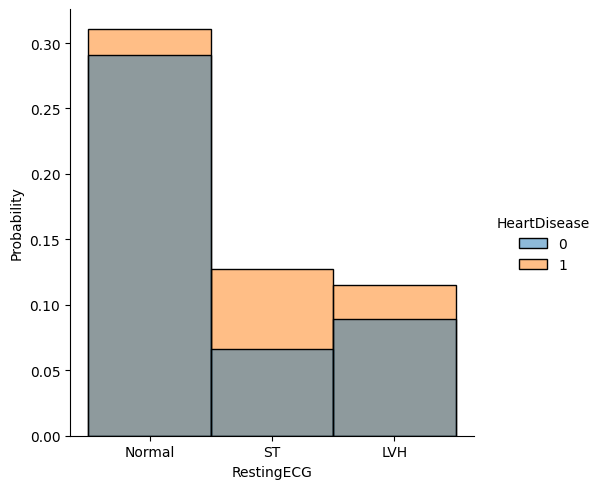

In [15]:
sns.displot(df,x="RestingECG",hue="HeartDisease",stat="probability")

In [16]:
''' 
    Noted features :
    Age
    Sex
    ChestPainType
    ExerciseAngina
    ST_SLope
    Oldpeak
    RestingBP
    MaxHR
'''

' \n    Noted features :\n    Age\n    Sex\n    ChestPainType\n    ExerciseAngina\n    ST_SLope\n    Oldpeak\n    RestingBP\n    MaxHR\n'

In [17]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

In [18]:
df_2 = df[['Age','Sex','ChestPainType','RestingBP','MaxHR','ExerciseAngina','Oldpeak','ST_Slope','HeartDisease']]
df_2.head(1)

,Age,Sex,ChestPainType,RestingBP,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,172,N,0.0,Up,0


In [19]:
# now we analyze the impact of each feature with another on heart disease

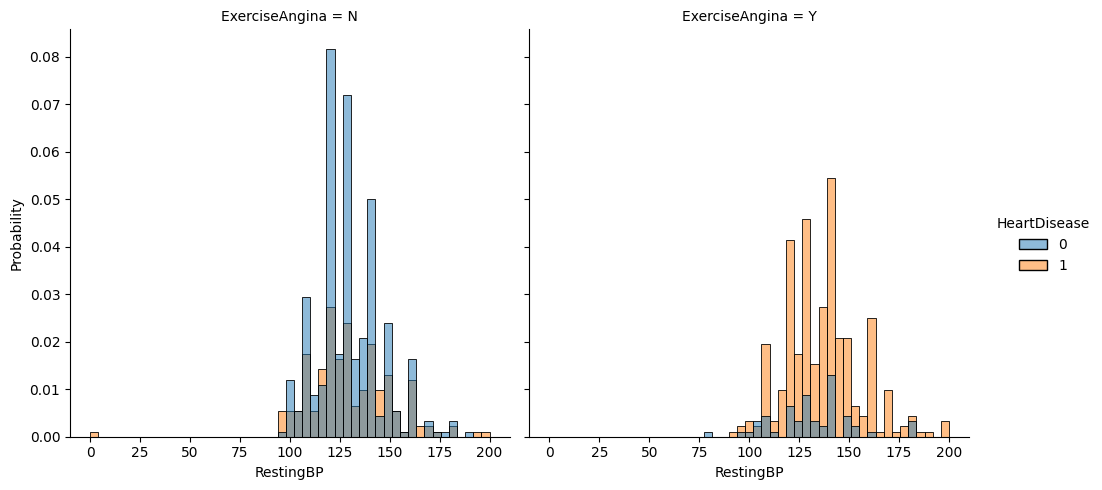

In [20]:
sns.displot(df_2,x="RestingBP",hue="HeartDisease",col="ExerciseAngina",stat="probability")

In [21]:
# impact of restingbp compared to exercise angina
bp_ex = df_2[['RestingBP','ExerciseAngina','HeartDisease']]

bp_ex_group_0 = bp_ex[bp_ex['HeartDisease']== 0]
bp_ex_group_1 = bp_ex[bp_ex['HeartDisease']== 1]

mean_0 = bp_ex_group_0['RestingBP'].mean()
mean_1 = bp_ex_group_1['RestingBP'].mean()

std_0 = bp_ex_group_0['RestingBP'].var()
std_1 = bp_ex_group_1['RestingBP'].var()

# Welch's t-test
n_0 = bp_ex_group_0.shape[0]
n_1 = bp_ex_group_1.shape[0]

t_val = (mean_0-mean_1)/np.sqrt((std_0/n_0)+(std_1/n_1))


# we need degrees of freedom df for p value
numerator = ((std_0/n_0)+(std_1/n_1)) **2
denominator = (((std_0/n_0) **2)/(n_0-1) + ((std_1/n_1) **2)/(n_1-1))
degrees_of_freedom = numerator/denominator

In [22]:
from scipy.stats import t
p_value = 2 * t.sf(abs(t_val), df=degrees_of_freedom)
p_value

np.float64(0.0008732264734356625)

In [23]:
angina_counts = df.groupby(['ExerciseAngina','HeartDisease']).size().reset_index(name='freq')
angina_counts

,ExerciseAngina,HeartDisease,freq
0,N,0,355
1,N,1,192
2,Y,0,55
3,Y,1,316


In [24]:
bp_ex_group_0.head()

,RestingBP,ExerciseAngina,HeartDisease
0,140,N,0
2,130,N,0
4,150,N,0
5,120,N,0
6,130,N,0


In [ ]:
bp_max_0 = bp_ex_group_0.RestingBP.max()
bp_max_1 = bp_ex_group_1.RestingBP.max()

print(f"bp_mean_0 : {bp_max_0}")
print(f"bp_mean_1 : {bp_max_1}")

bp_mean_0 : 190
bp_mean_1 : 200


In [34]:
bp_ex.describe()

,RestingBP,HeartDisease
count,918.000000,918.000000
mean,132.396514,0.553377
std,18.514154,0.497414
min,0.000000,0.000000
25%,120.000000,0.000000
50%,130.000000,1.000000
75%,140.000000,1.000000
max,200.000000,1.000000


In [35]:
bp_0 = bp_ex[bp_ex['RestingBP'] == 0]
bp_0.shape[0]

1

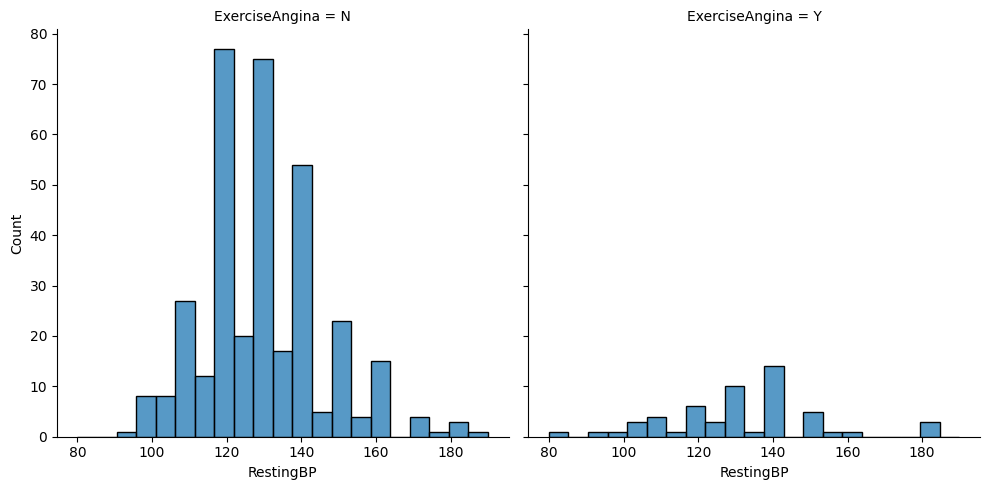

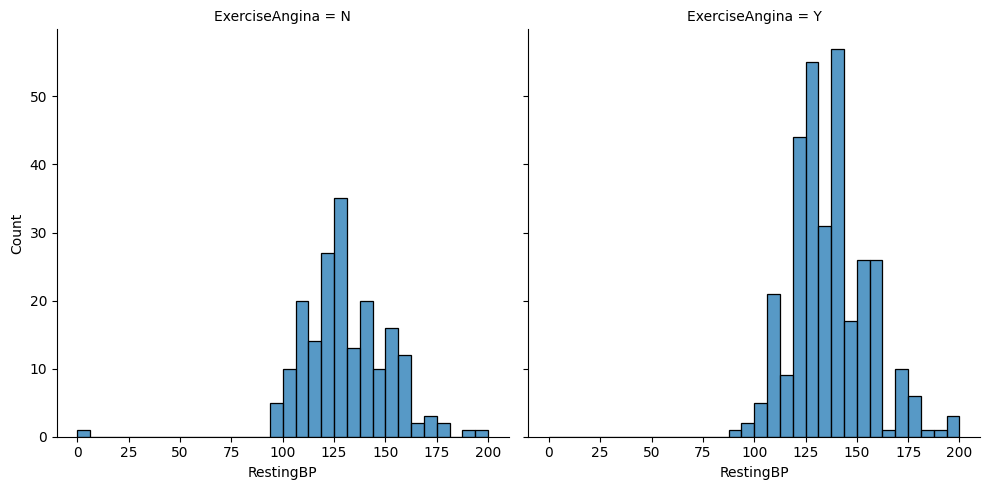

In [33]:
# each distribution
sns.displot(bp_ex_group_0,x="RestingBP",col="ExerciseAngina")
sns.displot(bp_ex_group_1,x="RestingBP",col="ExerciseAngina")

In [36]:
# restingbp and max hr
bp_hr = df[['RestingBP','MaxHR','HeartDisease']]
bp_hr.head()

,RestingBP,MaxHR,HeartDisease
0,140,172,0
1,160,156,1
2,130,98,0
3,138,108,1
4,150,122,0


<Axes: xlabel='RestingBP', ylabel='MaxHR'>

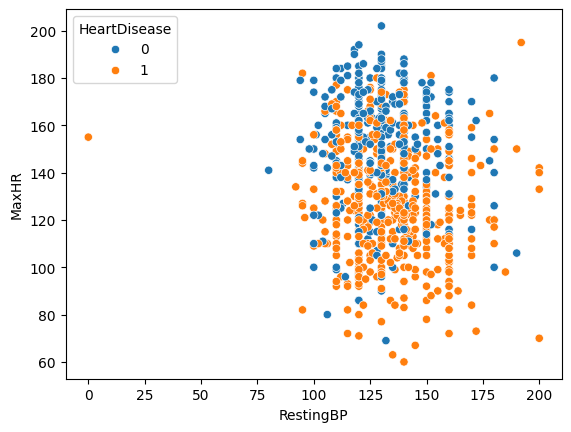

In [37]:
sns.scatterplot(data=bp_hr,x="RestingBP",y="MaxHR",hue="HeartDisease")

In [39]:
bp_hr['bphr_ratio'] = bp_hr['RestingBP']/bp_hr['MaxHR']
bp_hr.head()

C:\Users\KUSHANKUR\AppData\Local\Temp\ipykernel_2088\3599476905.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  bp_hr['bphr_ratio'] = bp_hr['RestingBP']/bp_hr['MaxHR']


,RestingBP,MaxHR,HeartDisease,bphr_ratio
0,140,172,0,0.813953
1,160,156,1,1.025641
2,130,98,0,1.326531
3,138,108,1,1.277778
4,150,122,0,1.229508


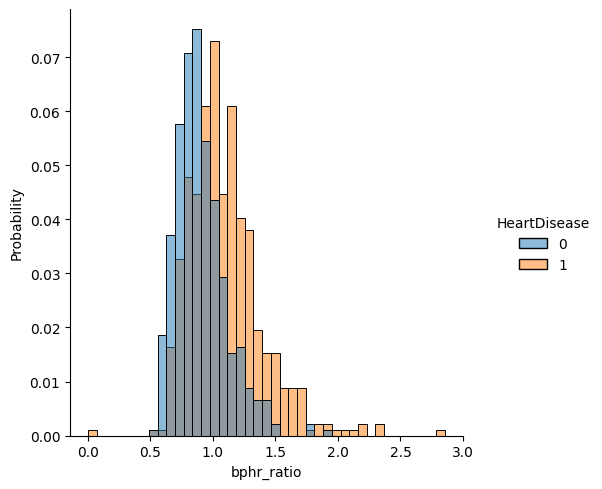

In [42]:
sns.displot(bp_hr,x="bphr_ratio",hue="HeartDisease",stat="probability")

In [ ]:
# note : the bp/maxhr ratio makes a huge impact on the heart disease

In [45]:
df['FastingBS'].value_counts()  # blood sugar level during fasting      0: Fasting blood sugar ≤ 120 mg/dL    1	Fasting blood sugar > 120 mg/dL

FastingBS
0    704
1    214
Name: count, dtype: int64

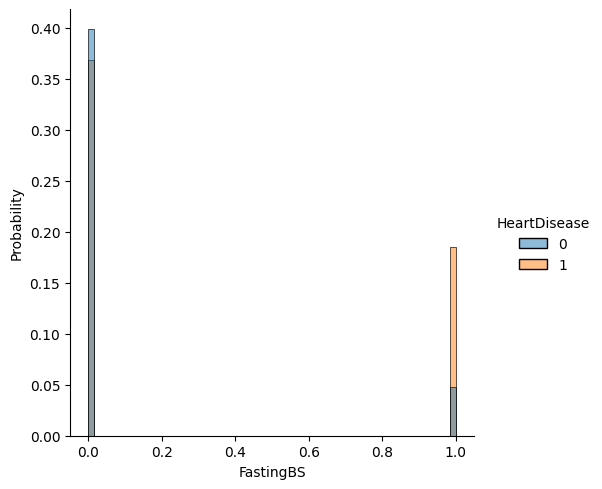

In [48]:
sns.displot(df,x="FastingBS",hue='HeartDisease',stat="probability")

In [53]:
df['Cholesterol'].describe()

count    918.000000
mean     198.799564
std      109.384145
min        0.000000
25%      173.250000
50%      223.000000
75%      267.000000
max      603.000000
Name: Cholesterol, dtype: float64

In [52]:
chol_0 = df[df['Cholesterol']==0]
chol_0.shape[0]

172

In [54]:
median_cholesterol = df.loc[
    df['Cholesterol'] != 0, 'Cholesterol'
].median()

df['Cholesterol'] = df['Cholesterol'].replace(
    0, median_cholesterol
)

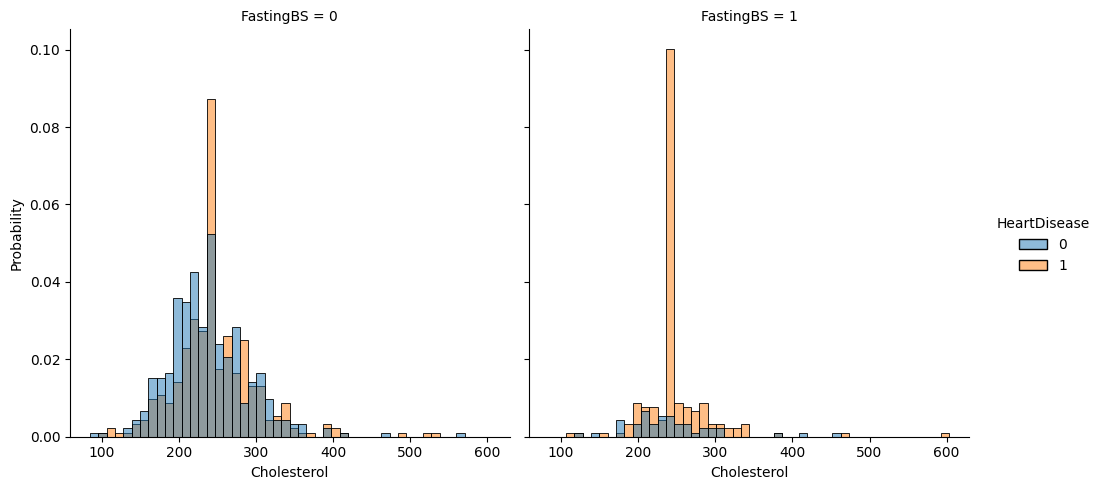

In [55]:
sns.displot(df,x="Cholesterol",col="FastingBS",hue="HeartDisease",stat="probability")